<h1 style="margin: 10px 0 30px 0">
Postlab 2: Electronic Spectroscopy and the Particle-in-a-Box
</h1>

Name: Aaron Joseph P. Gavino

### Note
To reproduce this notebook, KINDLY CLONE THE FOLLOWING GITHUB REPOSITORY: https://github.com/aarongavino-AJG/uv-vis.git. This is to ensure pathing and presence of data (.csv) files.

### Materials and methods

**Instrument:** Agilent Cary 3500 UV-Vis Spectrophotometer  
**Wavelength range:** $350$–$800\,\mathrm{nm}$  
**Data interval:** $1.00\,\mathrm{nm}$  
**Spectral bandwidth:** $1.00\,\mathrm{nm}$  
**Scan rate:** $600\,\mathrm{nm\,min^{-1}}$  
**Baseline/reference:** Deionized-water blank
**Cell path length:** $1.00\,\mathrm{cm}$
**Wavelength accuracy:** $\pm0.2\,\mathrm{nm}$

### Uncertainties

| Apparatus | Stated uncertainty |
|---|---:|
| $10\,\mathrm{mL}$ volumetric flask | $\pm0.03\,\mathrm{mL}$ |
| $25\,\mathrm{mL}$ volumetric flask | $\pm0.04\,\mathrm{mL}$ |
| $50\,\mathrm{mL}$ volumetric flask | $\pm0.06\,\mathrm{mL}$ |
| $5\,\mathrm{mL}$ pipette | $\pm0.05\,\mathrm{mL}$ |
| P200 micropipette | $\pm1\,\mathrm{\mu L}$ |
| Analytical balance | $\pm0.1\,\mathrm{mg}$ |

### Solution Concentrations
| Solution | Recorded preparation | Nominal concentration |
|---|---|---:|
| Methylene blue stock | $51.0\,\mathrm{mg}$ methylene blue chloride trihydrate in a $50.00\,\mathrm{mL}$ volumetric flask | $2.73\,\mathrm{mM}$ |
| Methylene blue working | $25.0\,\mathrm{\mu L}$ stock diluted to $10.00\,\mathrm{mL}$ | $6.82\,\mathrm{\mu M}$ |
| Methylene blue dilution | Approximately $1{:}1$ working solution and deionized water mixed in a cuvette | $\sim3.41\,\mathrm{\mu M}$ |
| Methyl orange stock | $0.1\%\,(w/v)$ methyl orange in ethanol | $3.05\,\mathrm{mM}$ |
| Methyl orange basic | $100.0\,\mathrm{\mu L}$ stock diluted to $25.00\,\mathrm{mL}$ | $12.2\,\mathrm{\mu M}$ |
| Methyl orange acidic | $9.00\,\mathrm{mL}$ basic solution and $1.00\,\mathrm{mL}$ approximately $1\,\mathrm{M}$ HCl, final volume $10.00\,\mathrm{mL}$ | $11.0\,\mathrm{\mu M}$ |

**Environment confirmation**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

h = 6.62607015e-34        # J s
c = 299792458.0           # m s^-1
m_e = 9.1093837015e-31    # kg
l_bond = 1.39e-10         # m, bond-equalised C-C length (Kuhn)

def load_spectrum(path):
    """Two-column CSV: wavelength / nm, absorbance. Returns a sorted DataFrame."""
    df = pd.read_csv(path)
    df.columns = ["wavelength_nm", "absorbance"]
    return df.sort_values("wavelength_nm").reset_index(drop=True)


def lambda_max(df, lo, hi, half=4):
    """Vertex of a parabola through +/- half points around the maximum in [lo, hi] nm."""
    win = df[(df.wavelength_nm >= lo) & (df.wavelength_nm <= hi)]
    w, a = win.wavelength_nm.to_numpy(), win.absorbance.to_numpy()
    i = int(np.argmax(a))
    s = slice(max(i - half, 0), i + half + 1)
    a2, a1, a0 = np.polyfit(w[s] - w[i], a[s], 2)
    return w[i] - a1 / (2 * a2)


def box_lambda_nm(N, L_m):
    """HOMO -> LUMO wavelength for N electrons in a box of length L (m)."""
    return 8 * m_e * c * L_m**2 / (h * (N + 1)) * 1e9


def box_length_m(N, lam_nm):
    """Box length (m) that reproduces lam_nm."""
    return np.sqrt(h * lam_nm * 1e-9 * (N + 1) / (8 * m_e * c))

### Parse Data

In [2]:
from pathlib import Path
import pandas as pd

source = Path("data") / "activity02.csv"

# Skip the sample labels and column headings.
raw = pd.read_csv(source, skiprows=2, header=None)

output_files = [
    "MB_rep1.csv",
    "MB_rep2.csv",
    "MB_rep3.csv",
    "MB_dilute.csv",
    "MO_basic.csv",
    "MO_acidic.csv",
]

if raw.shape[1] < 12:
    raise ValueError("Expected 12 columns: six wavelength–absorbance pairs.")

for i, filename in enumerate(output_files):
    spectrum = raw.iloc[:, 2 * i : 2 * i + 2].copy()
    spectrum.columns = ["wavelength_nm", "absorbance"]

    # Remove empty rows and check that remaining entries are numeric.
    spectrum = spectrum.dropna(how="all")
    spectrum = spectrum.apply(pd.to_numeric, errors="raise")

    if spectrum.isna().any().any():
        raise ValueError(f"Incomplete wavelength–absorbance pair in {filename}")

    spectrum = spectrum.sort_values("wavelength_nm").reset_index(drop=True)

    output_path = source.parent / filename
    spectrum.to_csv(output_path, index=False)

    print(f"Saved {output_path} — {len(spectrum)} points")

Saved data\MB_rep1.csv — 451 points
Saved data\MB_rep2.csv — 451 points
Saved data\MB_rep3.csv — 451 points
Saved data\MB_dilute.csv — 451 points
Saved data\MO_basic.csv — 451 points
Saved data\MO_acidic.csv — 451 points


### Plot Spectra

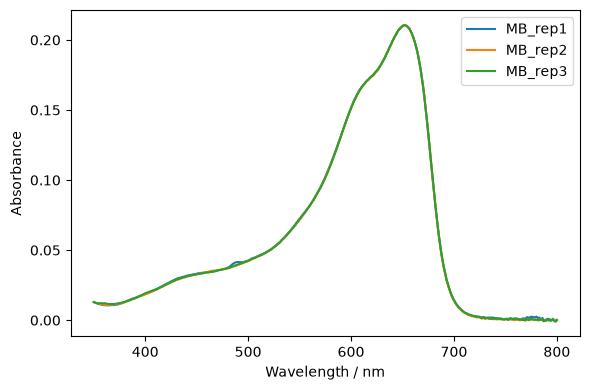

In [3]:
files = [
    "data/MB_rep1.csv",
    "data/MB_rep2.csv",
    "data/MB_rep3.csv",
]
spectra = {f: load_spectrum(f) for f in files}

fig, ax = plt.subplots(figsize=(6, 4))

for name, df in spectra.items():
    ax.plot(
        df.wavelength_nm,
        df.absorbance,
        label=Path(name).stem,
    )

ax.set_xlabel("Wavelength / nm")
ax.set_ylabel("Absorbance")
ax.legend()
fig.tight_layout()

Path("figures").mkdir(exist_ok=True)
fig.savefig("figures/MB_spectra.png", dpi=300)
plt.show()

In [4]:
lams = np.array([lambda_max(df, 640, 690) for df in spectra.values()])
lam = lams.mean()
u_rep = lams.std(ddof=1) / np.sqrt(len(lams))
u_cal = 0.2                     
u_lam = np.hypot(u_rep, u_cal)
print(f"lambda_max = {lam:.1f} +/- {u_lam:.1f} nm (n = {len(lams)})")

lit = 664.0                       # methylene blue monomer, water
print(f"deviation from literature: {100 * (lam - lit) / lit:+.1f} %")

lambda_max = 652.1 +/- 0.2 nm (n = 3)
deviation from literature: -1.8 %


In [5]:
def shoulder_ratio(df, lam_sh=612.0, lam_pk=664.0):
    a_sh, a_pk = np.interp(
        [lam_sh, lam_pk],
        df.wavelength_nm,
        df.absorbance,
    )
    return a_sh / a_pk

conc = load_spectrum("data/MB_rep1.csv")
dilute = load_spectrum("data/MB_dilute.csv")

print(
    f"A612/A664: {shoulder_ratio(conc):.3f} (working solution) "
    f"vs {shoulder_ratio(dilute):.3f} (diluted solution)"
)

A612/A664: 0.870 (working solution) vs 0.846 (diluted solution)


,Condition,pH,λmax (nm),u_fit (nm),u_λmax (nm),Acid (%),Base (%),Dominant form
0,MO basic,NaN,463.28,0.15,0.25,NaN,NaN,Enter measured pH
1,MO acidic,1.0,507.71,0.18,0.27,99.66,0.34,Acid


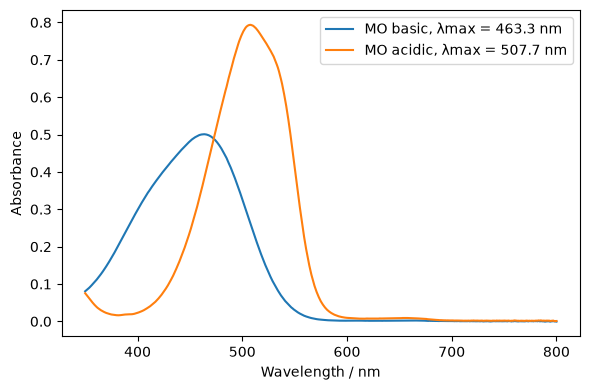

In [6]:
conditions = {
    "MO basic": {
        "file": "data/MO_basic.csv",
        "pH": None,
        "window": (430, 495),
    },
    "MO acidic": {
        "file": "data/MO_acidic.csv",
        "pH": 1.00,
        "window": (480, 560),
    },
}

pKa = 3.47
u_cal = 0.2

results = []

fig, ax = plt.subplots(figsize=(6, 4))

for name, condition in conditions.items():
    df = load_spectrum(condition["file"])
    lo, hi = condition["window"]

    lam = lambda_max(df, lo, hi, half=4)

    alternative_peaks = [
        lambda_max(df, lo, hi, half=half)
        for half in (2, 6)
    ]
    u_fit = max(abs(value - lam) for value in alternative_peaks)

    u_lam = np.hypot(u_cal, u_fit)

    ph = condition["pH"]

    if ph is None:
        acid_percent = np.nan
        base_percent = np.nan
        dominant_form = "Enter measured pH"
    else:
        acid_percent = 100 / (1 + 10**(ph - pKa))
        base_percent = 100 - acid_percent

        if acid_percent > 50:
            dominant_form = "Acid"
        elif acid_percent < 50:
            dominant_form = "Base"
        else:
            dominant_form = "Equal fractions"

    results.append({
        "Condition": name,
        "pH": ph,
        "λmax (nm)": lam,
        "u_fit (nm)": u_fit,
        "u_λmax (nm)": u_lam,
        "Acid (%)": acid_percent,
        "Base (%)": base_percent,
        "Dominant form": dominant_form,
    })

    ax.plot(
        df.wavelength_nm,
        df.absorbance,
        label=f"{name}, λmax = {lam:.1f} nm",
    )

results = pd.DataFrame(results)
display(results.round(2))

ax.set_xlabel("Wavelength / nm")
ax.set_ylabel("Absorbance")
ax.legend()
fig.tight_layout()

from pathlib import Path

Path("figures").mkdir(exist_ok=True)
fig.savefig("figures/MO_spectra.png", dpi=300)
plt.show()

In [7]:
p, N = 9, 12                      # methylene blue: para route through N10
L_geo = (p + 3) * l_bond
L_fit = box_length_m(N, lam)
u_L = L_fit * u_lam / (2 * lam)
alpha = L_fit / l_bond - (p + 3)

print(f"box prediction: {box_lambda_nm(N, L_geo):.0f} nm")
print(f"L_fit = {L_fit * 1e10:.2f} +/- {u_L * 1e10:.2f} Angstrom, alpha = {alpha:.2f} bonds")
print(f"N...N path {(p + 1) * l_bond * 1e10:.2f} A <= L_fit? {L_fit >= (p + 1) * l_bond}")

box prediction: 706 nm
L_fit = 14.15 +/- 0.00 Angstrom, alpha = -1.82 bonds
N...N path 13.90 A <= L_fit? True


### Data Summary

In [8]:
samples = {
    "MB replicate 1": ("data/MB_rep1.csv", 640, 690, 664.0),
    "MB replicate 2": ("data/MB_rep2.csv", 640, 690, 664.0),
    "MB replicate 3": ("data/MB_rep3.csv", 640, 690, 664.0),
    "MB diluted": ("data/MB_dilute.csv", 640, 690, 664.0),
    "MO basic": ("data/MO_basic.csv", 430, 495, 464.0),
    "MO acidic": ("data/MO_acidic.csv", 480, 560, 507.0),
}

u_cal = 0.2
rows = []
mb_peaks = []

for name, (file, lo, hi, reference) in samples.items():
    df = load_spectrum(file)
    lam = lambda_max(df, lo, hi, half=4)

    u_fit = max(
        abs(lambda_max(df, lo, hi, half=half) - lam)
        for half in (2, 6)
    )
    u_lam = np.hypot(u_cal, u_fit)

    rows.append({
        "Sample": name,
        "λmax (nm)": lam,
        "u_λmax (nm)": u_lam,
        "A at λmax": np.interp(lam, df.wavelength_nm, df.absorbance),
        "Reference λmax (nm)": reference,
        "Deviation (%)": 100 * (lam - reference) / reference,
        "A612/A664": (
            shoulder_ratio(df) if name.startswith("MB") else np.nan
        ),
    })

    if name.startswith("MB replicate"):
        mb_peaks.append([
            lambda_max(df, lo, hi, half=half)
            for half in (2, 4, 6)
        ])

summary = pd.DataFrame(rows)

# Combine replicate scatter, calibration, and fit-window sensitivity.
mb_peaks = np.array(mb_peaks)
mb_mean = mb_peaks[:, 1].mean()
u_rep = mb_peaks[:, 1].std(ddof=1) / np.sqrt(len(mb_peaks))
u_fit_mean = np.max(np.abs(mb_peaks.mean(axis=0) - mb_mean))
u_mb = np.sqrt(u_rep**2 + u_cal**2 + u_fit_mean**2)

display(summary.round(4))
print(f"MB mean λmax = {mb_mean:.1f} ± {u_mb:.1f} nm (n = 3)")
print("Single-scan uncertainties include calibration and fit-window sensitivity.")
print("Replicate variability is included in the MB mean uncertainty.")

summary.to_csv("data/UV_Vis_summary.csv", index=False)

,Sample,λmax (nm),u_λmax (nm),A at λmax,Reference λmax (nm),Deviation (%),A612/A664
0,MB replicate 1,652.1072,0.2752,0.2105,664.0,-1.7911,0.8695
1,MB replicate 2,651.9282,0.2424,0.2108,664.0,-1.8180,0.8704
2,MB replicate 3,652.1461,0.2692,0.2104,664.0,-1.7852,0.8721
3,MB diluted,652.5086,0.2934,0.1050,664.0,-1.7306,0.8461
4,MO basic,463.2832,0.2489,0.5007,464.0,-0.1545,NaN
5,MO acidic,507.7138,0.2693,0.7934,507.0,0.1408,NaN


MB mean λmax = 652.1 ± 0.3 nm (n = 3)
Single-scan uncertainties include calibration and fit-window sensitivity.
Replicate variability is included in the MB mean uncertainty.


AI Use Statement

Generative AI was used to debug and improve user-written code particularly in parsing the original csv file to maintain traceability. 